# Principal component analysis 
PCA (Principal component analysis) is a powerful tool often used in dimensionality reduction.

We will today use PCA to reduce the dimensionality of the Iris dataset from $X \in \mathbb{R}^4$ to $X' \in \mathbb{R}^2$.

In [3]:
import numpy as np
import sklearn as sk
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd

# plot data and fit (2d only)
def plot_fit(X, y, clf):
    """
    X = samples
    y = Ground truth
    clf = trained model
    """
    h = .02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    fig = plt.figure(1, figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)

    # Plot also the training points
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors= "black")
    plt.xlabel('Sepal length')
    plt.ylabel('Sepal width')
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.xticks(())
    plt.yticks(())

In [4]:
# import some data to play with
iris = sk.datasets.load_iris()
iris_df = pd.DataFrame(iris.data, columns = iris.feature_names)
display(iris_df)
X = StandardScaler().fit_transform(iris_df)
target = iris.target
print ("Number of samples ::", X.shape[0])
print("Number of features ::", X.shape[1])

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


Number of samples :: 150
Number of features :: 4


## Dimensionality reduction.
To use PCA in practice, simply use the following function:

```{Python}
pca = PCA(n_components = n )
principalComponents = pca.fit_transform(data_to_transform)

```
Find the documentation here: [sklearn PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)

In [11]:
###
# Code here
###
n = 2
pca = PCA(n_components=n)
pc = pca.fit_transform(X)


In [13]:
print(pc);

[[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]
 [-2.07563095  1.48917752]
 [-2.44402884  0.0476442 ]
 [-2.23284716  0.22314807]
 [-2.33464048 -1.11532768]
 [-2.18432817 -0.46901356]
 [-2.1663101   1.04369065]
 [-2.32613087  0.13307834]
 [-2.2184509  -0.72867617]
 [-2.6331007  -0.96150673]
 [-2.1987406   1.86005711]
 [-2.26221453  2.68628449]
 [-2.2075877   1.48360936]
 [-2.19034951  0.48883832]
 [-1.898572    1.40501879]
 [-2.34336905  1.12784938]
 [-1.914323    0.40885571]
 [-2.20701284  0.92412143]
 [-2.7743447   0.45834367]
 [-1.81866953  0.08555853]
 [-2.22716331  0.13725446]
 [-1.95184633 -0.62561859]
 [-2.05115137  0.24216355]
 [-2.16857717  0.52714953]
 [-2.13956345  0.31321781]
 [-2.26526149 -0.3377319 ]
 [-2.14012214 -0.50454069]
 [-1.83159477  0.42369507]
 [-2.61494794  1.79357586]
 [-2.44617739  2.15072788]
 [-2.10997488 -0.46020184]
 [-2.2078089  -0.2061074 ]
 [-2.04514621  0.66155811]
 

Plot the principal components and compare them to X:

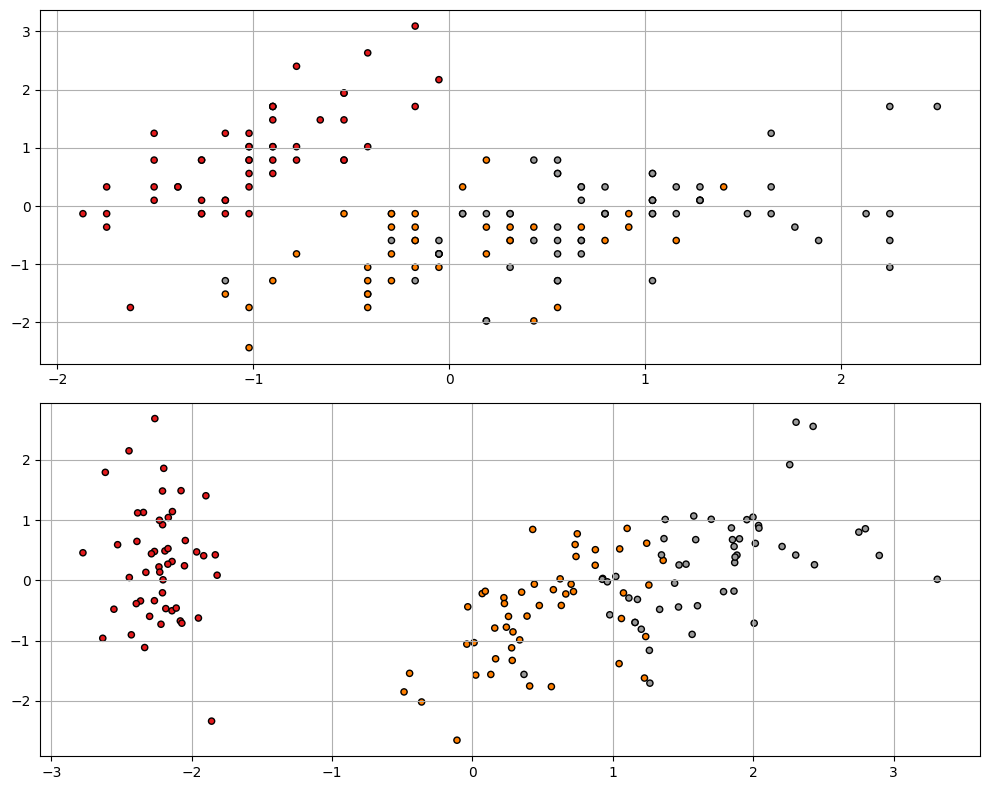

In [20]:
###
# code here
# replace x, y and x1, y1 with the values from your computed pca and your X
###plt.scatter(PC, c = target,cmap = plt.cm.Set1, edgecolor = 'black', s = 20)


fig = plt.figure(1, figsize=(10, 8))
ax = plt.subplot(211)

#Plot scaled version

g = plt.scatter(X[:,0], X[:,1], c = target, cmap = plt.cm.Set1, edgecolor = 'black', s = 20)
plt.grid()
plt.subplot(212)

# Plot principal components
plt.scatter(pc[:,0], pc[:,1], c = target,cmap = plt.cm.Set1, edgecolor = 'black', s = 20)
plt.grid()
plt.tight_layout()
plt.show()

## Explained Variance
The explained variance tells you how much information (variance) can be attributed to each of the principal components. 

By using the attribute `explained_variance_ratio_`, you can see that the first principal component explains 72.77% of the variance and the second principal component explains 23.03% of the variance.

In [22]:
print(pca.explained_variance_ratio_)

print(sum(pca.explained_variance_ratio_))

[0.72962445 0.22850762]
0.9581320720000166


So, in total our PCA has now expressed 96% of the variance of the dataset.
We can use these new components to attempt to fit an SVM like we did in the previous exercise. The lower dimensional data should retain most of the information in the original data and therefore should compete close to on par with a classifier trained on all features.

## Exercises
### 1) SVM
Apply an SVM to the principal components. How does it perform compared to using only two features per sample?

In [31]:
train, test, ytrain, ytest = train_test_split(pc, target, test_size = 0.4)

In [ ]:
C = 1.0
gamma = "scale"
degree = 3
clf = sk.svm.LinearSVC(penalty="l2", loss="squared_hinge", random_state=0, max_iter=int(1e5))
svc = sk.svm.SVC(kernel="linear", C=C)
rbf_svc = sk.svm.SVC(kernel="rbf", gamma = gamma, C=C)
poly_svc = sk.svm.SVC(kernel='poly', degree=degree, C=C)
models = {"linear": svc, "rbf": rbf_svc, "poly": poly_svc, "clf": clf}

for name, model in models.items():
    model.fit(train, ytrain)
    print(name, "training data:", model.score(train, ytrain))
    print(name, "test data:",     model.score(test, ytest))

linear training data: 0.9333333333333333
linear test data: 0.9333333333333333
rbf training data: 0.9333333333333333
rbf test data: 0.9166666666666666
poly training data: 0.9111111111111111
poly test data: 0.9
clf training data: 0.9
clf test data: 0.8666666666666667


## 2) Three principal components
Attempt with three principal components. 
How much of the variance of the data do these express? 

Again, make a 3D plot where each point is colored respective to the predicted class from your SVM.

In [38]:
pca = PCA(n_components=3)
pc = pca.fit_transform(X)
print("explained variance:",pca.explained_variance_ratio_)
print("explained variance:",sum(pca.explained_variance_ratio_))
train, test, ytrain, ytest = train_test_split(pc, target, test_size = 0.4)
C = 2.54
gamma = "scale"
degree = 3
clf = sk.svm.LinearSVC(penalty="l2", loss="squared_hinge", random_state=0, max_iter=int(1e5), C=C)
svc = sk.svm.SVC(kernel="linear", C=C)
rbf_svc = sk.svm.SVC(kernel="rbf", gamma = gamma, C=C)
poly_svc = sk.svm.SVC(kernel='poly', degree=degree, C=C)
models = {"linear": svc, "rbf": rbf_svc, "poly": poly_svc, "clf": clf}

for name, model in models.items():
    model.fit(train, ytrain)
    print(name, "training data:", model.score(train, ytrain))
    print(name, "test data:",     model.score(test, ytest))



explained variance: [0.72962445 0.22850762 0.03668922]
explained variance: 0.9948212908928454
linear training data: 0.9777777777777777
linear test data: 0.95
rbf training data: 0.9666666666666667
rbf test data: 0.9333333333333333
poly training data: 1.0
poly test data: 0.8666666666666667
clf training data: 0.9666666666666667
clf test data: 0.9666666666666667



## 3) Best accuracy
Compare all the different SVM's we have trained. What is the best accuracy you can acheive?. You are also allowed to use different kernels!

## 4) Grid search
Attempt to perform a grid search with the function provided by `sklearn`.
The `gridsearch` function will try a lot of different combinations of parameters for your SVM so you don't have to.
```{Python}
from sklearn.model_selection import GridSearchCV
import numpy as np
    
c = np.logspace(start = -15, stop = 1000, base = 1.02)
param_grid = {'C': c}

grid = GridSearchCV(clf, param_grid = param_grid, cv = 3, n_jobs = -1, scoring = 'accuracy')
grid.fit(X_train, y_train)
```
[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)


Are you able to get a better fit?

In [ ]:
from sklearn.model_selection import GridSearchCV
import numpy as np

c = np.logspace(start = -15, stop = 1000, base = 1.02)
param_grid = {'C': c}

grid = GridSearchCV(clf, param_grid = param_grid, cv = 3, n_jobs = -1, scoring = 'accuracy')
grid.fit(train, ytrain)
grid.scoring()
grid = GridSearchCV(poly_svc, param_grid = param_grid, cv = 3, n_jobs = -1, scoring = 'accuracy')
grid.fit(train, ytrain)

,estimator,"SVC(C=2.54, kernel='poly')"
,param_grid,{'C': array([7.4301...98264652e+08])}
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,np.float64(8.707147749903895)


LinearSVC   best params: {'C': np.float64(0.0017782794100389228)}
            CV accuracy: 0.889   test accuracy: 0.733
SVC linear  best params: {'C': np.float64(0.5623413251903491)}
            CV accuracy: 0.922   test accuracy: 0.850
SVC rbf     best params: {'C': np.float64(316.22776601683796), 'gamma': np.float64(0.1)}
            CV accuracy: 0.933   test accuracy: 0.900
SVC poly    best params: {'C': np.float64(100.0), 'degree': 3}
            CV accuracy: 0.944   test accuracy: 0.900


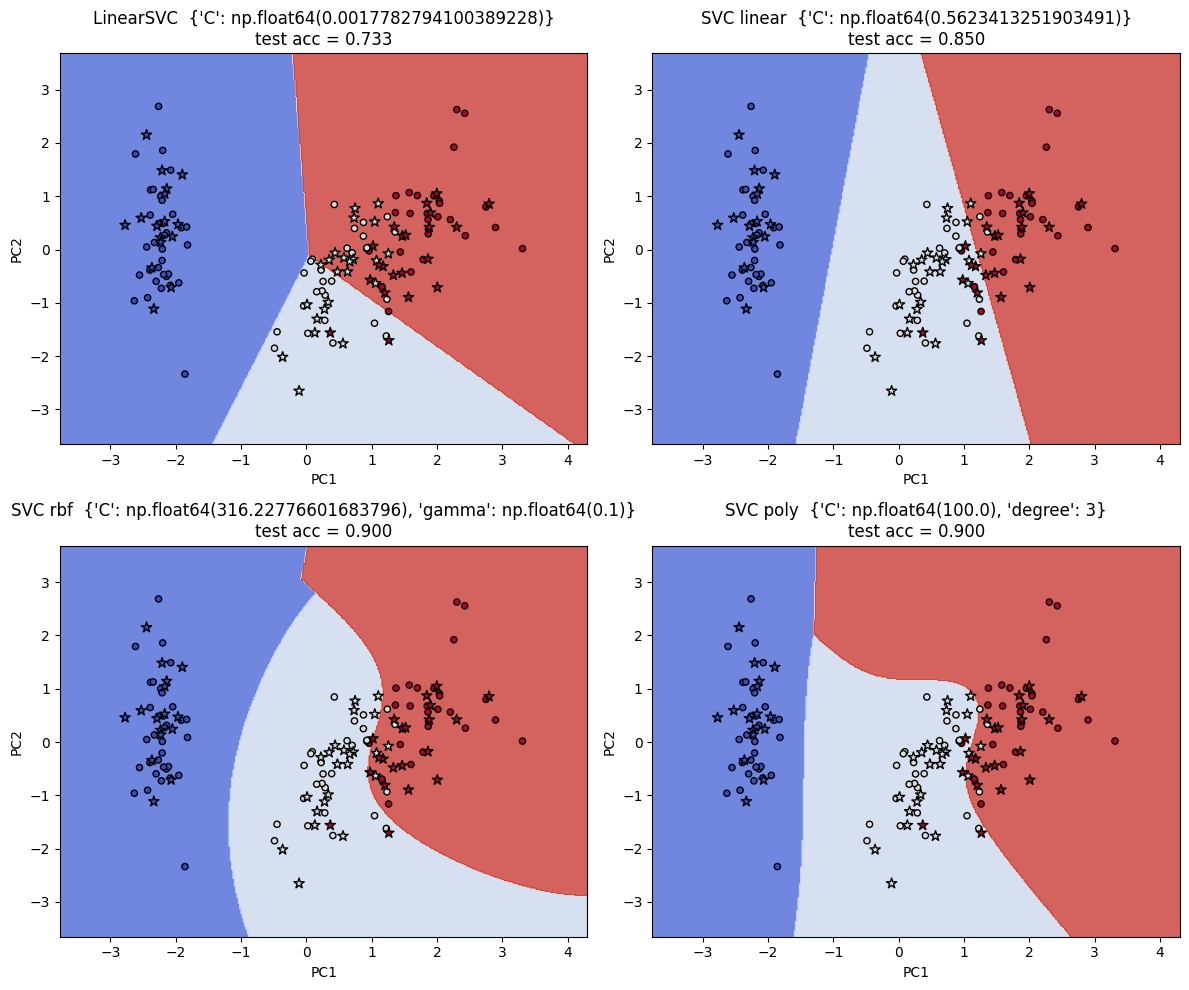

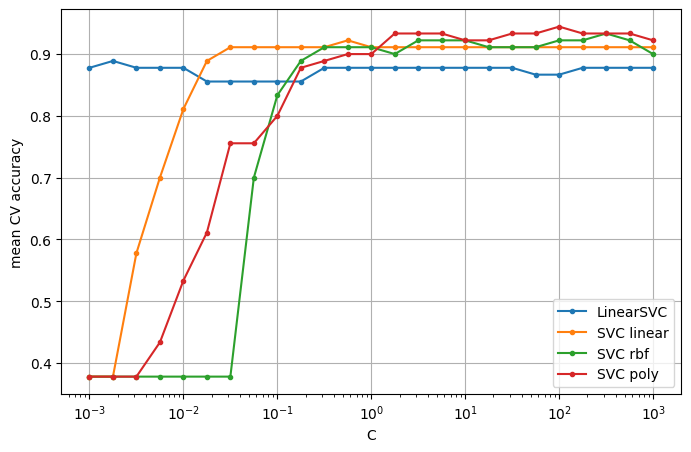

In [42]:
from sklearn.model_selection import GridSearchCV

# 2-PC data just for the grid search (cell 15 overwrites pc/train with 3 PCs)
pc2 = PCA(n_components=2).fit_transform(X)
train2, test2, ytrain2, ytest2 = train_test_split(pc2, target, test_size=0.4, random_state=0)

c = np.logspace(-3, 3, 25)   # C from 0.001 to 1000
searches = {
    "LinearSVC":  (sk.svm.LinearSVC(max_iter=int(1e5), random_state=0),
                   {"C": c}),
    "SVC linear": (sk.svm.SVC(kernel="linear"),
                   {"C": c}),
    "SVC rbf":    (sk.svm.SVC(kernel="rbf"),
                   {"C": c, "gamma": np.logspace(-3, 2, 11)}),
    "SVC poly":   (sk.svm.SVC(kernel="poly"),
                   {"C": c, "degree": [2, 3, 4]}),
}

grids = {}
for name, (model, param_grid) in searches.items():
    grid = GridSearchCV(model, param_grid=param_grid, cv=3, n_jobs=-1, scoring="accuracy")
    grid.fit(train2, ytrain2)
    grids[name] = grid
    print(f"{name:11s} best params: {grid.best_params_}")
    print(f"{'':11s} CV accuracy: {grid.best_score_:.3f}   test accuracy: {grid.score(test2, ytest2):.3f}")

# Decision boundaries of the best model from each search
h = .02
xx, yy = np.meshgrid(np.arange(pc2[:, 0].min() - 1, pc2[:, 0].max() + 1, h),
                     np.arange(pc2[:, 1].min() - 1, pc2[:, 1].max() + 1, h))
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, grid) in zip(axes.ravel(), grids.items()):
    Z = grid.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
    ax.scatter(train2[:, 0], train2[:, 1], c=ytrain2, cmap=plt.cm.coolwarm, edgecolors="black", s=20)
    ax.scatter(test2[:, 0], test2[:, 1], c=ytest2, cmap=plt.cm.coolwarm, edgecolors="black", s=60, marker="*")
    ax.set_title(f"{name}  {grid.best_params_}\ntest acc = {grid.score(test2, ytest2):.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

# CV accuracy as a function of C (other params fixed at their best value)
plt.figure(figsize=(8, 5))
for name, grid in grids.items():
    res = grid.cv_results_
    others = {k: v for k, v in grid.best_params_.items() if k != "C"}
    mask = np.all([res[f"param_{k}"] == v for k, v in others.items()], axis=0) if others else np.ones(len(res["params"]), bool)
    plt.semilogx(np.array(res["param_C"][mask], dtype=float), res["mean_test_score"][mask], marker="o", ms=3, label=name)
plt.xlabel("C"); plt.ylabel("mean CV accuracy"); plt.legend(); plt.grid()
plt.show()
